# Modularity on the Karate Club Graph
### Recursive Spectral Community Detection from Scratch
**DSC212: Graph Theory Module – Research Assignment**

**Name:** M Sri Hari Venkatesh **Roll No.:** IMS25207

---
### Contents
0. Introduction and the Karate Club story
1. Setup, data and the modularity matrix
2. Why modularity? (cut size vs. modularity)
3. The null model, checked by simulation
4. Properties of $B$ checked numerically (Propositions 1–2, Corollary 1)
5. Spectral bisection (Rayleigh–Ritz) – the first split in detail
6. Exactness of $\Delta Q$: handout block vs. Newman's generalised matrix
7. Recursive spectral partitioning (main algorithm, split tree)
8. Visualisation after every split
9. Evaluation against the ground truth and against other algorithms
10. Node metrics after each split
11. Evolution of the metrics (line, bar, heat-map, rank plots)
12. Which nodes stay central? Community-level analysis
13. Extension: vertex-move refinement
14. Discussion
15. Exam-preparation Q&A
16. References

> Runs top to bottom with no manual edits. Needs only `numpy`, `networkx`, `matplotlib`, `pandas` (all preinstalled in Google Colab). Figures are also saved as PNG files next to the notebook.

## 0. Introduction
**The data.** In the early 1970s the anthropologist Wayne Zachary spent two years observing 34 members of a university karate club. An edge joins two members who interacted regularly outside class (78 edges). During the study a dispute between the instructor (**Mr. Hi**, node 0) and the club president (the **Officer**, node 33) split the club in two. The friendship network was recorded *before* the split, so it is a natural test: *can a method that sees only the graph recover the faction split that really happened?*

**The idea.** Cutting the fewest edges is a bad community criterion (it isolates a single unlucky vertex). **Modularity** instead compares the number of edges *inside* groups with the number expected in a random graph that has the same degrees:
$$B_{ij}=A_{ij}-\frac{k_ik_j}{2m},\qquad Q=\frac1{4m}\,s^\top B s,\quad s\in\{-1,+1\}^n .$$
Maximising $Q$ over all $2^n$ labelings is infeasible, so we relax $s$ to a real unit vector, solve it with the **leading eigenvector** of $B$ (Rayleigh–Ritz), round by sign, and recurse on each part while the leading eigenvalue of the restricted matrix stays positive (Newman 2006).

**Tasks of the assignment** (all done below): implement the recursive method; visualise the graph after each split; compute degree, betweenness, closeness and clustering after each split; plot their evolution; discuss which nodes stay central and how community structure influences the metrics.

## 1. Setup, data and the modularity matrix

In [1]:
import numpy as np
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from collections import deque, Counter

np.set_printoptions(precision=4, suppress=True, linewidth=140)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print("networkx", nx.__version__, "| numpy", np.__version__)

networkx 3.7 | numpy 2.4.6


NetworkX ships Zachary's graph. Each node has a `club` attribute (`'Mr. Hi'` or `'Officer'`), the faction it really joined. **It is used only for evaluation, never by the algorithm.** Newer NetworkX versions also attach edge weights; the handout uses the plain 0/1 graph, so we remove them.

In [2]:
G = nx.karate_club_graph()
for _, _, d in G.edges(data=True):
    d.pop("weight", None)                     # plain 0/1 graph as in the handout

nodes = sorted(G.nodes())                     # 0..33
n, m = G.number_of_nodes(), G.number_of_edges()
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # adjacency matrix, entries in {0,1}
k = A.sum(axis=1)                             # degree vector
B = A - np.outer(k, k) / (2 * m)              # modularity matrix

truth = np.array([0 if G.nodes[i]["club"] == "Mr. Hi" else 1 for i in nodes])
print(f"n = {n} nodes, m = {m} edges, 2m = {int(2*m)} stubs, sum of degrees = {int(k.sum())}")
print(f"density = {nx.density(G):.3f}, avg degree = {k.mean():.2f}, max degree = {int(k.max())} (node {int(k.argmax())})")
print("diameter =", nx.diameter(G), "| connected:", nx.is_connected(G))
print("Ground truth faction sizes (Mr. Hi, Officer):", np.bincount(truth))
print("Top-5 degrees (degree, node):", sorted([(int(d), int(v)) for d, v in zip(k, nodes)], reverse=True)[:5])

n = 34 nodes, m = 78 edges, 2m = 156 stubs, sum of degrees = 156
density = 0.139, avg degree = 4.59, max degree = 17 (node 33)
diameter = 5 | connected: True
Ground truth faction sizes (Mr. Hi, Officer): [17 17]
Top-5 degrees (degree, node): [(17, 33), (16, 0), (12, 32), (10, 2), (9, 1)]


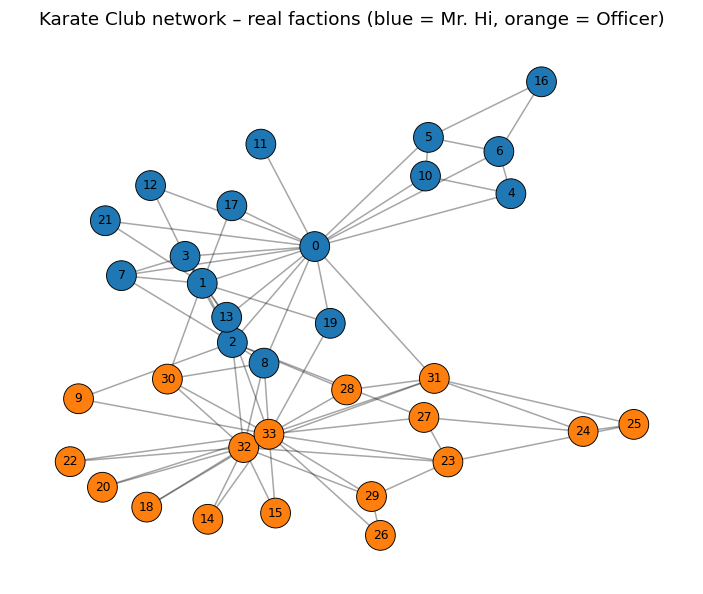

In [3]:
# A first look at the network, coloured by the real faction
pos = nx.spring_layout(G, seed=42)            # ONE fixed layout reused in every figure
palette = list(mpl.colormaps["tab10"].colors)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[palette[t] for t in truth], node_size=380,
                       edgecolors="k", linewidths=0.6, node_shape="o")
nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
ax.set_title("Karate Club network – real factions (blue = Mr. Hi, orange = Officer)")
ax.axis("off"); plt.tight_layout(); plt.savefig("karate_ground_truth.png", bbox_inches="tight"); plt.show()

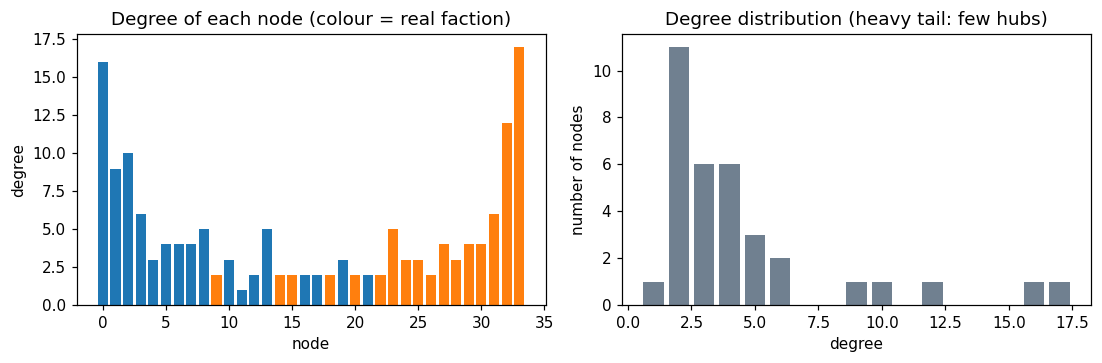

In [4]:
# Degree distribution
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(nodes, k, color=[palette[t] for t in truth]); ax[0].set_xlabel("node"); ax[0].set_ylabel("degree")
ax[0].set_title("Degree of each node (colour = real faction)")
cnt = Counter(k.astype(int))
ax[1].bar(list(cnt.keys()), list(cnt.values()), color="slategray")
ax[1].set_xlabel("degree"); ax[1].set_ylabel("number of nodes"); ax[1].set_title("Degree distribution (heavy tail: few hubs)")
plt.tight_layout(); plt.savefig("degree_distribution.png"); plt.show()

## 2. Why modularity? Cut size vs. modularity
The smallest possible cut isolates one vertex. Node 11 has degree 1, so splitting it off cuts a single edge, a "perfect" cut that is clearly not a community. Below we compare it with the first spectral split (computed in Section 5, quickly recomputed here).

In [5]:
def modularity(communities, B, m):
    # Q = (1/2m) * sum_c sum_{i,j in c} B_ij   (communities = list of lists of node indices)
    return sum(B[np.ix_(c, c)].sum() for c in communities) / (2 * m)

def cut_size(S, G):
    S = set(S)
    return sum(1 for u, v in G.edges() if (u in S) != (v in S))

# (a) isolate the lowest-degree vertex
v = int(k.argmin())
iso = [[v], [i for i in nodes if i != v]]
# (b) the spectral split (leading eigenvector of B, split by sign)
w, V = np.linalg.eigh(B); u1 = V[:, -1]
spec = [[i for i in nodes if u1[i] > 0], [i for i in nodes if u1[i] <= 0]]
# (c) the real split
real = [[i for i in nodes if truth[i] == 0], [i for i in nodes if truth[i] == 1]]

print(f"{'split':<28}{'sizes':>10}{'edges cut':>12}{'modularity Q':>16}")
for name, p in [("isolate node %d (min cut)" % v, iso), ("spectral split", spec), ("real faction split", real)]:
    print(f"{name:<28}{str([len(p[0]), len(p[1])]):>10}{cut_size(p[0], G):>12}{modularity(p, B, m):>16.4f}")

split                            sizes   edges cut    modularity Q
isolate node 11 (min cut)      [1, 33]           1         -0.0001
spectral split                [16, 18]          10          0.3715
real faction split            [17, 17]          11          0.3582


The min-cut "split" removes only one edge but has $Q\approx0$ (no better than not splitting at all), while the spectral split cuts ten edges yet has far higher modularity ($Q\approx0.37$). Cutting few edges is not the goal; cutting *fewer edges than chance would predict, relative to the group sizes and degrees* is.

## 3. The null model, checked by simulation
The null model gives every vertex $k_i$ "stubs" and pairs the $2m$ stubs uniformly at random (the *configuration model*). The text derives $\mathbb E[\#\text{edges}(i,j)]=k_ik_j/2m$. We verify this by drawing many random graphs with `networkx.configuration_model` and averaging the number of edges between each pair.

trials: 3000
max |empirical - k_i k_j/2m| over off-diagonal pairs: 0.0419
correlation of empirical vs. predicted expectations : 0.9994


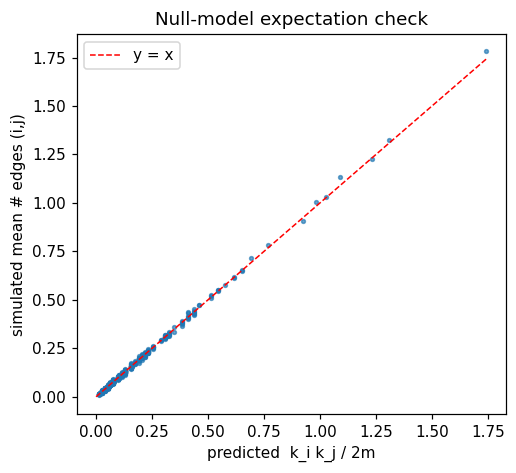

In [6]:
rng_seed = 0
degseq = [int(x) for x in k]
trials = 3000
acc = np.zeros((n, n))
for t in range(trials):
    M = nx.configuration_model(degseq, seed=rng_seed + t)        # random stub pairing (multigraph)
    for u, v in M.edges():
        if u != v:
            acc[u, v] += 1; acc[v, u] += 1
emp = acc / trials
exp = np.outer(k, k) / (2 * m)
mask = ~np.eye(n, dtype=bool)
print("trials:", trials)
print("max |empirical - k_i k_j/2m| over off-diagonal pairs:", round(np.abs(emp - exp)[mask].max(), 4))
print("correlation of empirical vs. predicted expectations :", round(np.corrcoef(emp[mask], exp[mask])[0, 1], 5))

fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(exp[mask], emp[mask], s=6, alpha=.4)
lim = exp[mask].max()
ax.plot([0, lim], [0, lim], "r--", lw=1, label="y = x")
ax.set_xlabel("predicted  k_i k_j / 2m"); ax.set_ylabel("simulated mean # edges (i,j)")
ax.set_title("Null-model expectation check"); ax.legend(); plt.tight_layout()
plt.savefig("null_model_check.png"); plt.show()

The points lie on the line $y=x$ (tiny residual from the exact pairing probability $k_ik_j/(2m-1)$ and Monte-Carlo noise), confirming the formula used in $B$.

## 4. Properties of $B$ checked numerically
* **Proposition 1:** $B$ is real symmetric ⇒ (Theorem 1) real eigenvalues and an orthonormal eigenbasis.
* **Proposition 2:** $B\mathbf 1=0$ (row sums of $B$ vanish), so $0$ is always an eigenvalue of the *global* $B$.
* **Corollary 1:** the trivial partition $s=\mathbf 1$ has $Q=0$.

In [7]:
print("Prop 1  B symmetric                    :", np.allclose(B, B.T))
w_all, V_all = np.linalg.eigh(B)              # eigh: for symmetric matrices, ascending real eigenvalues
print("Thm 1   eigenvalues real (eigh)        :", np.isrealobj(w_all))
print("Thm 1   V^T V = I (orthonormal basis)  :", np.allclose(V_all.T @ V_all, np.eye(n)))
print("Thm 1   B = V diag(w) V^T              :", np.allclose(V_all @ np.diag(w_all) @ V_all.T, B))
print("Prop 2  max |row sum of B|             :", np.abs(B.sum(axis=1)).max())
print("Prop 2  smallest |eigenvalue| (should be ~0):", np.abs(w_all).min())
print("Cor 1   Q(trivial) = 1^T B 1 / 4m      :", np.ones(n) @ B @ np.ones(n) / (4 * m))
print("\nNumber of positive eigenvalues:", int((w_all > 1e-10).sum()), "| zero:", int((np.abs(w_all) <= 1e-10).sum()),
      "| negative:", int((w_all < -1e-10).sum()))

Prop 1  B symmetric                    : True
Thm 1   eigenvalues real (eigh)        : True
Thm 1   V^T V = I (orthonormal basis)  : True
Thm 1   B = V diag(w) V^T              : True
Prop 2  max |row sum of B|             : 8.881784197001252e-16
Prop 2  smallest |eigenvalue| (should be ~0): 6.276052305191211e-17
Cor 1   Q(trivial) = 1^T B 1 / 4m      : 1.120898246015783e-17

Number of positive eigenvalues: 11 | zero: 11 | negative: 12


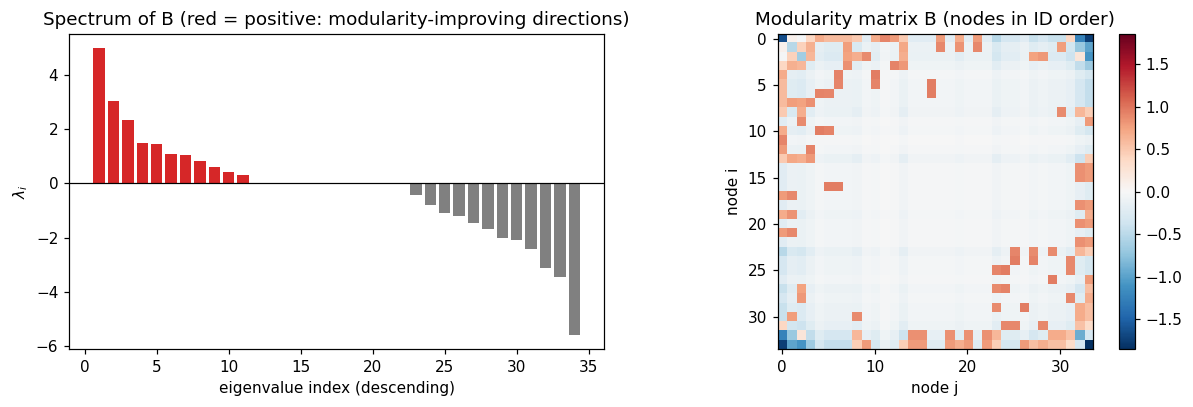

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(range(1, n + 1), w_all[::-1], color=["tab:red" if x > 1e-10 else "grey" for x in w_all[::-1]])
ax[0].axhline(0, color="k", lw=.8); ax[0].set_xlabel("eigenvalue index (descending)")
ax[0].set_ylabel(r"$\lambda_i$"); ax[0].set_title("Spectrum of B (red = positive: modularity-improving directions)")
im = ax[1].imshow(B, cmap="RdBu_r", vmin=-abs(B).max(), vmax=abs(B).max())
ax[1].set_title("Modularity matrix B (nodes in ID order)"); ax[1].set_xlabel("node j"); ax[1].set_ylabel("node i")
plt.colorbar(im, ax=ax[1], fraction=0.046); plt.tight_layout(); plt.savefig("spectrum_and_B.png"); plt.show()

## 5. Spectral bisection – the first split in detail
**Rayleigh–Ritz (Theorem 2).** For unit vectors, $\max_{\|s\|_2=1}s^\top Bs=\lambda_1$, attained at the leading eigenvector $u_1$. Writing $s=\sum\alpha_iu_i$ gives $s^\top Bs=\sum\alpha_i^2\lambda_i\le\lambda_1$. We verify this numerically, then round $u_1$ by sign.

In [9]:
lam1, u1 = w_all[-1], V_all[:, -1]
print("lambda_1 =", round(lam1, 5))

# Numerical check of Rayleigh-Ritz: no random unit vector beats lambda_1
rng = np.random.default_rng(0)
R = rng.normal(size=(20000, n)); R /= np.linalg.norm(R, axis=1, keepdims=True)
vals = np.einsum("ij,jk,ik->i", R, B, R)
print("max over 20000 random unit vectors of s^T B s :", round(vals.max(), 4), "<= lambda_1 =", round(lam1, 4))
print("u1^T B u1 =", round(u1 @ B @ u1, 4))

# Rounding: s_i = +1 if (u1)_i > 0 else -1
s = np.where(u1 > 0, 1, -1)
print("Q of the rounded split     :", round(s @ B @ s / (4 * m), 4))
print("Upper bound lambda_1 * n / 4m (relaxation):", round(lam1 * n / (4 * m), 4))

# Compare with random +-1 labelings
rs = rng.choice([-1, 1], size=(20000, n))
Qr = np.einsum("ij,jk,ik->i", rs, B, rs) / (4 * m)
print(f"random +-1 labelings: mean Q = {Qr.mean():.3f}, best of 20000 = {Qr.max():.3f}  vs spectral {s @ B @ s / (4*m):.3f}")

lambda_1 = 4.97708
max over 20000 random unit vectors of s^T B s : 1.8604 <= lambda_1 = 4.9771
u1^T B u1 = 4.9771
Q of the rounded split     : 0.3715
Upper bound lambda_1 * n / 4m (relaxation): 0.5424
random +-1 labelings: mean Q = -0.024, best of 20000 = 0.192  vs spectral 0.371


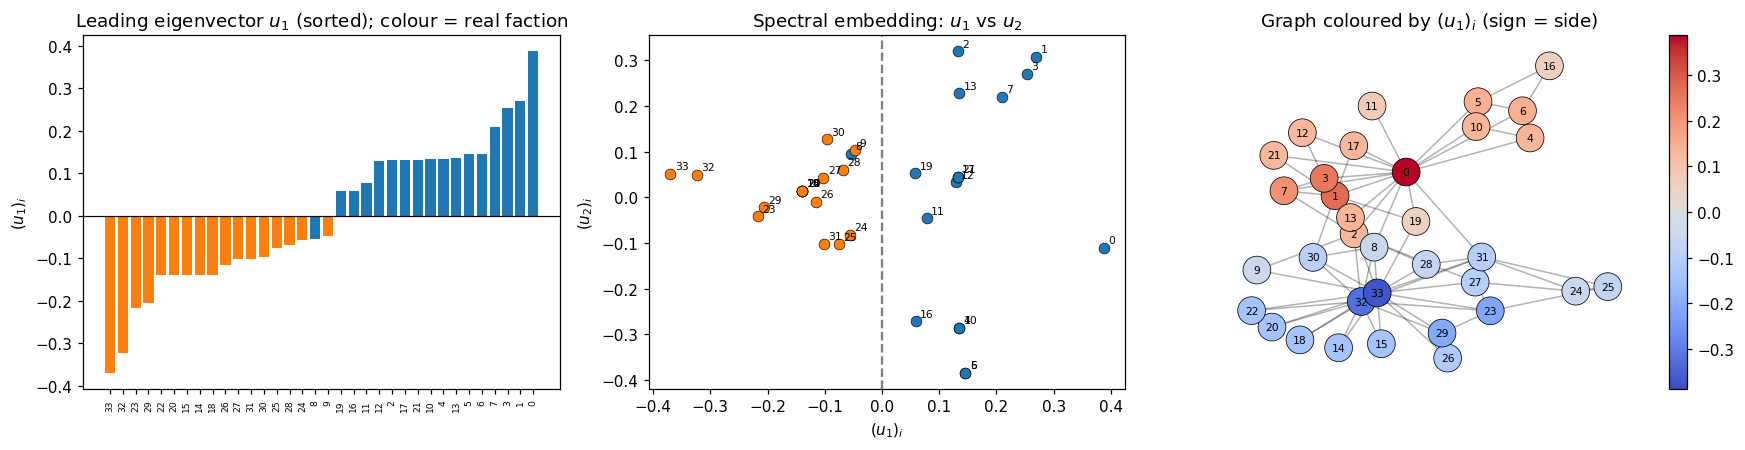

Nodes with |(u1)_i| closest to 0 (least certain assignment): [9, 8, 24, 19, 16] [-0.048 -0.054 -0.056  0.058  0.059]


In [10]:
# The leading eigenvector as a "soft assignment", and a 2-D spectral embedding (u1 vs u2)
u2 = V_all[:, -2]
order = np.argsort(u1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

ax[0].bar(range(n), u1[order], color=[palette[truth[i]] for i in order])
ax[0].set_xticks(range(n)); ax[0].set_xticklabels(order, fontsize=6, rotation=90)
ax[0].axhline(0, color="k", lw=.8); ax[0].set_title("Leading eigenvector $u_1$ (sorted); colour = real faction")
ax[0].set_ylabel("$(u_1)_i$")

for i in nodes:
    ax[1].scatter(u1[i], u2[i], color=palette[truth[i]], s=50, edgecolors="k", linewidths=.4)
    ax[1].annotate(str(i), (u1[i], u2[i]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[1].axvline(0, color="grey", ls="--"); ax[1].set_xlabel("$(u_1)_i$"); ax[1].set_ylabel("$(u_2)_i$")
ax[1].set_title("Spectral embedding: $u_1$ vs $u_2$")

nodes_c = nx.draw_networkx_nodes(G, pos, ax=ax[2], node_color=u1, cmap="coolwarm", node_size=330,
                                 edgecolors="k", linewidths=.5, vmin=-abs(u1).max(), vmax=abs(u1).max())
nx.draw_networkx_edges(G, pos, ax=ax[2], alpha=.3); nx.draw_networkx_labels(G, pos, ax=ax[2], font_size=7)
ax[2].set_title("Graph coloured by $(u_1)_i$ (sign = side)"); ax[2].axis("off")
plt.colorbar(nodes_c, ax=ax[2], fraction=.046)
plt.tight_layout(); plt.savefig("leading_eigenvector.png", bbox_inches="tight"); plt.show()

near0 = [int(i) for i in np.argsort(np.abs(u1))[:5]]
print("Nodes with |(u1)_i| closest to 0 (least certain assignment):", near0, np.round(u1[near0], 3))

Nodes at the far ends of $u_1$ are firmly in one camp; nodes with $(u_1)_i\approx0$ are ambiguous, and these are where classification errors occur (node 8 sits near the boundary).

## 6. Exactness of $\Delta Q$: handout block vs. Newman's generalised matrix
Splitting a group $C$ by $s\in\{\pm1\}^{|C|}$ changes modularity by
$$\Delta Q=\frac{1}{2m}\Big(\sum_{C^+}B_{ij}+\sum_{C^-}B_{ij}-\sum_{C}B_{ij}\Big)=\frac1{4m}\Big(s^\top B_C s-\mathbf 1^\top B_C\mathbf 1\Big)=\frac1{4m}s^\top B^{(g)}s,$$
with the **generalised** matrix $B^{(g)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$ (indices in $C$). For $C=V$ the row sums vanish so $B^{(g)}=B$; for a proper subgroup they do not, so the handout's plain block $B_C$ gives $\frac1{4m}s^\top B_Cs=\Delta Q+\frac1{4m}\mathbf 1^\top B_C\mathbf 1$, which is *not* the exact gain. We check this numerically on a random split of a random subgroup.

In [11]:
rng = np.random.default_rng(1)
C = sorted(rng.choice(n, size=14, replace=False).tolist())
sC = rng.choice([-1, 1], size=len(C))
Cp = [c for c, x in zip(C, sC) if x == 1]; Cm = [c for c, x in zip(C, sC) if x == -1]

BC = B[np.ix_(C, C)]
Bg = BC - np.diag(BC.sum(axis=1))
dQ_true  = modularity([Cp, Cm], B, m) - modularity([C], B, m)        # difference of two real partitions' modularity (rest unchanged)
dQ_gen   = sC @ Bg @ sC / (4 * m)
dQ_block = sC @ BC @ sC / (4 * m)
print(f"true  Delta Q             = {dQ_true:+.6f}")
print(f"generalised  s^T B^(g) s/4m = {dQ_gen:+.6f}   (exact)")
print(f"plain block  s^T B_C s /4m  = {dQ_block:+.6f}   (off by 1^T B_C 1 / 4m = {np.ones(len(C)) @ BC @ np.ones(len(C)) / (4*m):+.6f})")
print("identity holds:", np.isclose(dQ_true, dQ_gen))

true  Delta Q             = +0.000822
generalised  s^T B^(g) s/4m = +0.000822   (exact)
plain block  s^T B_C s /4m  = -0.020895   (off by 1^T B_C 1 / 4m = -0.021717)
identity holds: True


The handout uses the plain block (and its eigenvalue test). We follow the handout by default (`generalized=False`) and additionally run Newman's exact version for comparison. In both cases we add the safeguard of Newman's paper: the rounded split is accepted only if its *true* $\Delta Q>0$.

## 7. Recursive spectral partitioning (main algorithm)
**For each group $C$ (processed first-in-first-out):**
1. Form $B^{(C)}$ and compute its eigenpairs with `numpy.linalg.eigh`.
2. If $\lambda_1^{(C)}\le0$ (tolerance $10^{-10}$) ⇒ indivisible.
3. Else split by the sign of $u_1^{(C)}$; if one side is empty ⇒ indivisible.
4. Safeguard: accept only if the true $\Delta Q>0$.
5. Push both parts on the queue.

One accepted split = one *iteration*; iteration 0 is the unsplit graph. Every iteration stores the whole partition and its modularity.

In [12]:
TOL = 1e-10

def restricted_B(C, B, generalized=False):
    # Restricted modularity matrix B^(C) (|C| x |C|); optional Newman diagonal correction
    BC = B[np.ix_(C, C)].copy()
    if generalized:
        BC -= np.diag(BC.sum(axis=1))
    return BC

def bisect(C, B, m_total, generalized=False):
    # Try to split group C. Returns (C_plus, C_minus, lambda1, dQ); parts are None if no split.
    BC = restricted_B(C, B, generalized)
    w, V = np.linalg.eigh(BC)
    lam1, u1 = w[-1], V[:, -1]
    if lam1 <= TOL:
        return None, None, lam1, 0.0
    s = np.where(u1 > 0, 1, -1)
    Cp = [c for c, si in zip(C, s) if si == 1]
    Cm = [c for c, si in zip(C, s) if si == -1]
    if len(Cp) == 0 or len(Cm) == 0:
        return None, None, lam1, 0.0
    dQ = (B[np.ix_(Cp, Cp)].sum() + B[np.ix_(Cm, Cm)].sum() - B[np.ix_(C, C)].sum()) / (2 * m_total)
    if dQ <= TOL:
        return None, None, lam1, dQ
    return Cp, Cm, lam1, dQ

def recursive_bisection(B, m, generalized=False, verbose=True):
    # Returns (history, final_communities, log). history[i] = partition after i splits.
    n = B.shape[0]
    final, queue, log = [], deque([list(range(n))]), []
    history = [dict(iter=0, communities=[list(range(n))], Q=0.0)]
    it = 0
    while queue:
        C = queue.popleft()
        Cp, Cm, lam1, dQ = bisect(C, B, m, generalized)
        if Cp is None:
            final.append(C)
            log.append(dict(parent=tuple(C), kids=None, lam1=lam1, dQ=dQ, iter=None))
            if verbose: print(f"      group of size {len(C):2d}: lambda1 = {lam1:+.4f} -> indivisible (leaf)")
            continue
        it += 1
        queue.extend([Cp, Cm])
        comms = [g for g in list(queue) + final]
        Q = modularity(comms, B, m)
        history.append(dict(iter=it, communities=[sorted(g) for g in comms], Q=Q))
        log.append(dict(parent=tuple(C), kids=(tuple(Cp), tuple(Cm)), lam1=lam1, dQ=dQ, iter=it))
        if verbose:
            print(f"iter {it}: split size {len(C):2d} (lambda1 = {lam1:+.4f}, dQ = {dQ:+.4f}) -> {len(Cp)} + {len(Cm)};  Q = {Q:.4f}")
    return history, [sorted(c) for c in final], log

print("=== Handout version (plain restricted block B^(C)) ===")
history, final_comms, log = recursive_bisection(B, m, generalized=False)
print("\nFinal communities:")
for i, c in enumerate(sorted(final_comms, key=min)):
    print(f"  C{i+1} (size {len(c):2d}): {c}")
Q_final = modularity(final_comms, B, m)
print(f"\nFinal modularity Q = {Q_final:.4f} with {len(final_comms)} communities after {len(history)-1} splits")
print("check vs networkx:", round(nx.community.modularity(G, [set(c) for c in final_comms]), 4))

=== Handout version (plain restricted block B^(C)) ===
iter 1: split size 34 (lambda1 = +4.9771, dQ = +0.3715) -> 16 + 18;  Q = 0.3715
iter 2: split size 16 (lambda1 = +2.9441, dQ = +0.0183) -> 10 + 6;  Q = 0.3898
iter 3: split size 18 (lambda1 = +2.5041, dQ = +0.0183) -> 5 + 13;  Q = 0.4081
      group of size 10: lambda1 = +2.5712 -> indivisible (leaf)
iter 4: split size  6 (lambda1 = +2.1480, dQ = +0.0013) -> 1 + 5;  Q = 0.4094
      group of size  5: lambda1 = +1.8759 -> indivisible (leaf)
      group of size 13: lambda1 = +2.3563 -> indivisible (leaf)
      group of size  1: lambda1 = -0.0064 -> indivisible (leaf)
      group of size  5: lambda1 = +2.1470 -> indivisible (leaf)

Final communities:
  C1 (size 10): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  C2 (size  5): [4, 5, 6, 10, 16]
  C3 (size 13): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  C4 (size  1): [11]
  C5 (size  5): [24, 25, 27, 28, 31]

Final modularity Q = 0.4094 with 5 communities after 4 splits
check vs networ

### Split tree
The recursion defines a binary tree. Leaves are the final communities; each internal node is annotated with the leading eigenvalue that justified the split.

In [13]:
by_parent = {e["parent"]: e for e in log}
def print_tree(group, indent=0):
    e = by_parent[tuple(group)]
    pad = "    " * indent
    if e["kids"] is None:
        print(f"{pad}└─ LEAF  size {len(group):2d}: {sorted(group)}")
    else:
        print(f"{pad}├─ iter {e['iter']}: size {len(group):2d}  lambda1={e['lam1']:+.3f}  dQ={e['dQ']:+.4f}")
        for kid in e["kids"]:
            print_tree(kid, indent + 1)
print_tree(range(n))

├─ iter 1: size 34  lambda1=+4.977  dQ=+0.3715
    ├─ iter 2: size 16  lambda1=+2.944  dQ=+0.0183
        └─ LEAF  size 10: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
        ├─ iter 4: size  6  lambda1=+2.148  dQ=+0.0013
            └─ LEAF  size  1: [11]
            └─ LEAF  size  5: [4, 5, 6, 10, 16]
    ├─ iter 3: size 18  lambda1=+2.504  dQ=+0.0183
        └─ LEAF  size  5: [24, 25, 27, 28, 31]
        └─ LEAF  size 13: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]


## 8. Visualisation after every split
The same fixed spring layout is used every time, so only the colours change. Nodes are labelled by ID; each panel's title shows the number of communities and the modularity $Q$.

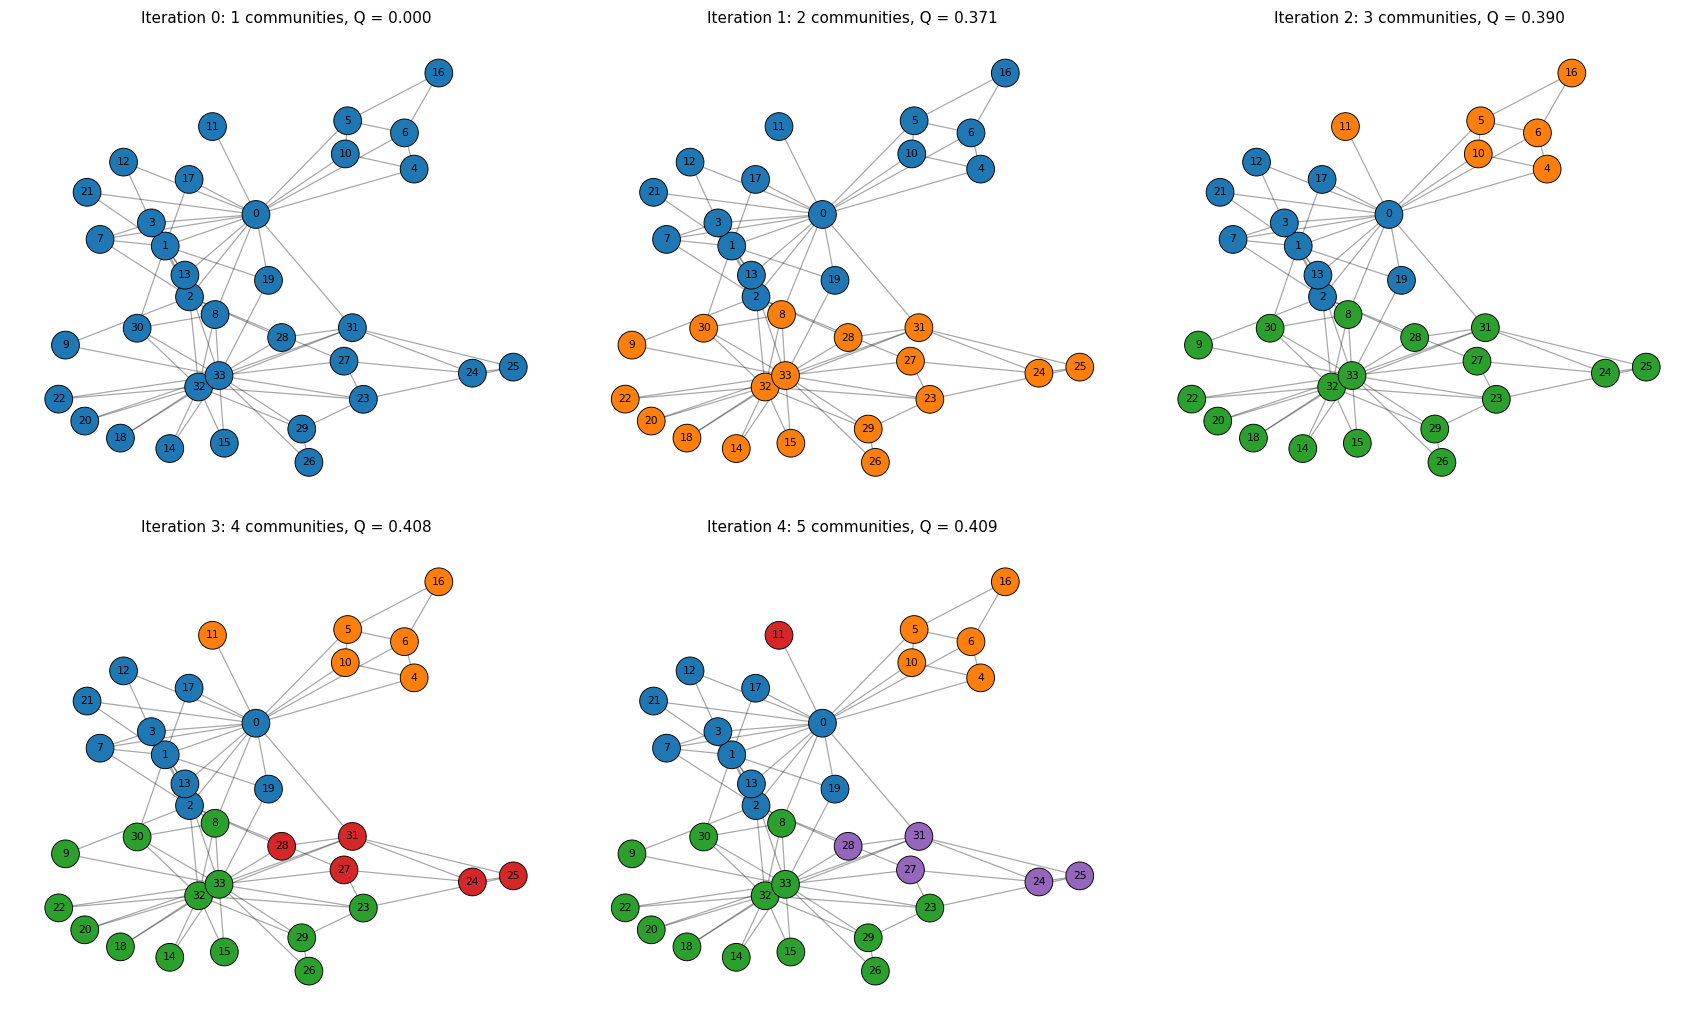

In [14]:
def community_labels(communities):
    lab = {}
    for cid, c in enumerate(sorted(communities, key=min)):
        for v in c:
            lab[v] = cid
    return lab

def draw_partition(ax, communities, title, highlight=None):
    lab = community_labels(communities)
    colors = [palette[lab[v] % len(palette)] for v in nodes]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=0.8)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=330, edgecolors="k", linewidths=0.6)
    if highlight:
        nx.draw_networkx_nodes(G, pos, nodelist=highlight, ax=ax, node_color="none", node_size=520,
                               edgecolors="red", linewidths=2)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(title, fontsize=10); ax.axis("off")

ncols = 3
nrows = int(np.ceil(len(history) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.7 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, h in zip(axes, history):
    draw_partition(ax, h["communities"], f"Iteration {h['iter']}: {len(h['communities'])} communities, Q = {h['Q']:.3f}")
for ax in axes[len(history):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("partition_evolution.png", bbox_inches="tight"); plt.show()

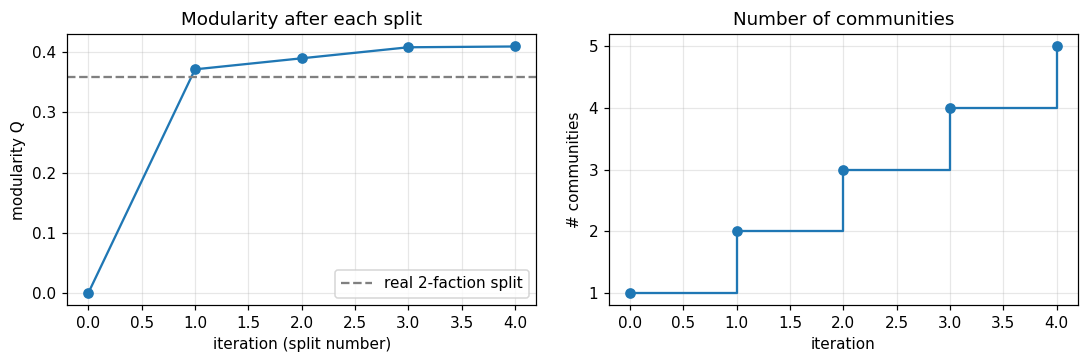

 iteration  communities      Q   gain
         0            1 0.0000 0.0000
         1            2 0.3715 0.3715
         2            3 0.3898 0.0183
         3            4 0.4081 0.0183
         4            5 0.4094 0.0013


In [15]:
# Modularity and number of communities along the recursion
iters = [h["iter"] for h in history]
Qs = [h["Q"] for h in history]
ncom = [len(h["communities"]) for h in history]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(iters, Qs, "o-"); ax[0].set_xlabel("iteration (split number)"); ax[0].set_ylabel("modularity Q")
ax[0].axhline(modularity(real, B, m), color="grey", ls="--", label="real 2-faction split"); ax[0].legend()
ax[0].set_title("Modularity after each split"); ax[0].grid(alpha=.3)
ax[1].step(iters, ncom, where="post", marker="o"); ax[1].set_xlabel("iteration"); ax[1].set_ylabel("# communities")
ax[1].set_title("Number of communities"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("modularity_vs_iteration.png"); plt.show()

print(pd.DataFrame({"iteration": iters, "communities": ncom, "Q": np.round(Qs, 4),
                    "gain": np.round(np.diff([0] + Qs), 4)}).to_string(index=False))

## 9. Evaluation against the ground truth and against other algorithms
We measure agreement with the real factions with the **Adjusted Rand Index (ARI)** and **Normalised Mutual Information (NMI)**, both implemented from the definitions (no extra libraries), and compare with NetworkX's greedy modularity and Louvain algorithms.

In [16]:
def contingency(a, b):
    ua, ia = np.unique(a, return_inverse=True); ub, ib = np.unique(b, return_inverse=True)
    M = np.zeros((len(ua), len(ub)))
    for x, y in zip(ia, ib): M[x, y] += 1
    return M

def ari(a, b):
    M = contingency(a, b); c2 = lambda x: x * (x - 1) / 2
    sum_ij = c2(M).sum(); sa = c2(M.sum(1)).sum(); sb = c2(M.sum(0)).sum(); tot = c2(M.sum())
    exp = sa * sb / tot; mx = (sa + sb) / 2
    return (sum_ij - exp) / (mx - exp) if mx != exp else 1.0

def nmi(a, b):
    M = contingency(a, b); N = M.sum(); P = M / N
    pa, pb = P.sum(1), P.sum(0)
    nz = P > 0
    I = (P[nz] * np.log(P[nz] / np.outer(pa, pb)[nz])).sum()
    H = lambda p: -(p[p > 0] * np.log(p[p > 0])).sum()
    return 2 * I / (H(pa) + H(pb)) if (H(pa) + H(pb)) > 0 else 1.0

def labels_from(communities):
    lab = np.zeros(n, dtype=int)
    for cid, c in enumerate(communities):
        for v in c: lab[v] = cid
    return lab

rows = []
def add(name, comms):
    comms = [sorted(c) for c in comms]
    lab = labels_from(comms)
    rows.append({"method": name, "#communities": len(comms), "Q": round(modularity(comms, B, m), 4),
                 "ARI vs factions": round(ari(lab, truth), 3), "NMI vs factions": round(nmi(lab, truth), 3)})

add("Ground truth (2 factions)", real)
add("Spectral – 1st split only (iteration 1)", history[1]["communities"])
add("Spectral – final (handout block)", final_comms)
_, final_gen, _ = recursive_bisection(B, m, generalized=True, verbose=False)
add("Spectral – final (Newman generalised)", final_gen)
add("NetworkX greedy_modularity_communities", [list(c) for c in nx.community.greedy_modularity_communities(G)])
add("NetworkX louvain_communities (seed=1)", [list(c) for c in nx.community.louvain_communities(G, seed=1)])
results = pd.DataFrame(rows).set_index("method")
results

,#communities,Q,ARI vs factions,NMI vs factions
method,,,,
Ground truth (2 factions),2,0.3582,1.000,1.000
Spectral – 1st split only (iteration 1),2,0.3715,0.882,0.837
Spectral – final (handout block),5,0.4094,0.446,0.565
Spectral – final (Newman generalised),4,0.3934,0.435,0.579
NetworkX greedy_modularity_communities,3,0.3807,0.568,0.565
NetworkX louvain_communities (seed=1),4,0.4188,0.392,0.490


First split agrees with the real factions on 97.1% of members (33/34).
Misclassified: [8]
  node 8 (real: Mr. Hi) has neighbours [0, 2, 30, 32, 33] with factions ['Mr. Hi', 'Mr. Hi', 'Officer', 'Officer', 'Officer']


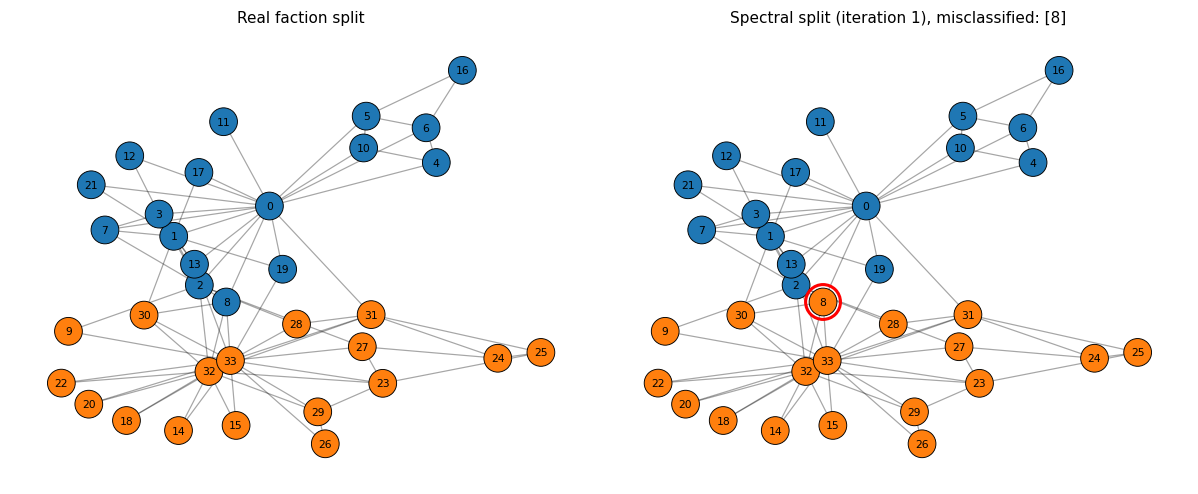

In [17]:
# First split in detail: who is misclassified?
first = history[1]["communities"]
pred = labels_from(first)
agree = (pred == truth).mean()
flip = agree < 0.5
mis = [int(i) for i in np.where((pred == truth) if flip else (pred != truth))[0]]
print(f"First split agrees with the real factions on {max(agree, 1-agree):.1%} of members ({n-len(mis)}/{n}).")
print("Misclassified:", mis)
for v in mis:
    nb = sorted(G[v])
    print(f"  node {v} (real: {G.nodes[v]['club']}) has neighbours {nb} with factions "
          f"{[G.nodes[u]['club'] for u in nb]}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
draw_partition(ax[0], real, "Real faction split")
draw_partition(ax[1], first, f"Spectral split (iteration 1), misclassified: {mis}", highlight=mis)
plt.tight_layout(); plt.savefig("first_split_vs_truth.png", bbox_inches="tight"); plt.show()

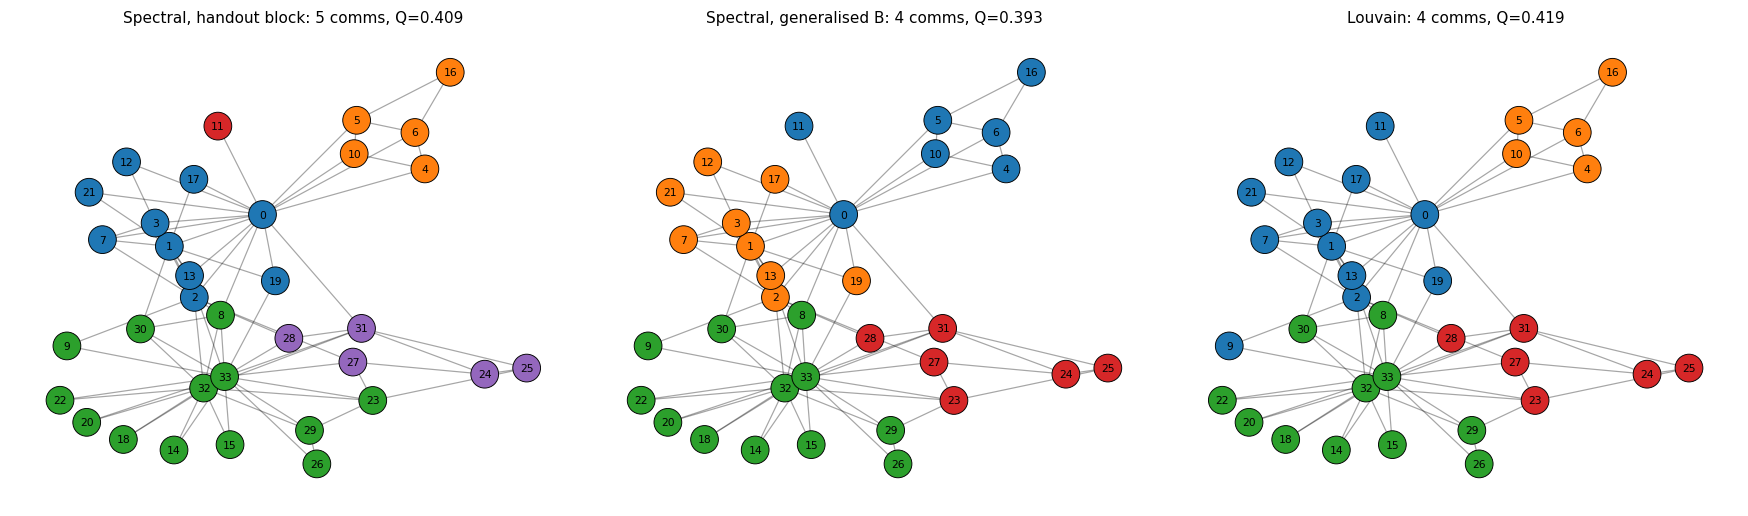

In [18]:
# Final partitions side by side: handout block vs Newman generalised vs Louvain
louv = [sorted(c) for c in nx.community.louvain_communities(G, seed=1)]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
draw_partition(ax[0], final_comms, f"Spectral, handout block: {len(final_comms)} comms, Q={modularity(final_comms,B,m):.3f}")
draw_partition(ax[1], final_gen,   f"Spectral, generalised B: {len(final_gen)} comms, Q={modularity(final_gen,B,m):.3f}")
draw_partition(ax[2], louv,        f"Louvain: {len(louv)} comms, Q={modularity(louv,B,m):.3f}")
plt.tight_layout(); plt.savefig("final_comparison.png", bbox_inches="tight"); plt.show()

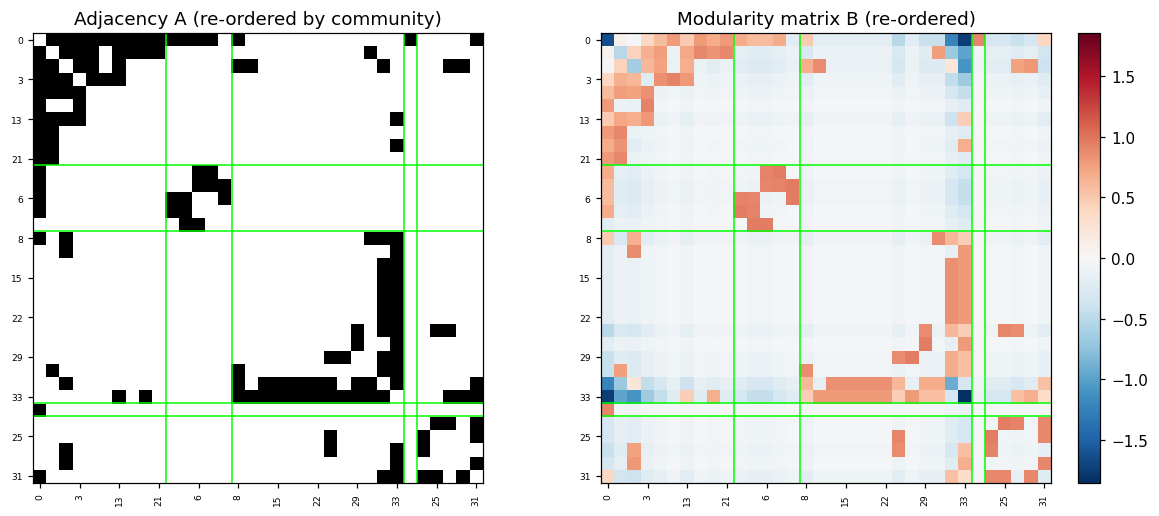

In [19]:
# Block structure: adjacency matrix re-ordered by the final communities
order = [v for c in sorted(final_comms, key=min) for v in c]
bounds = np.cumsum([len(c) for c in sorted(final_comms, key=min)])[:-1] - 0.5
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
for a, M, ttl in [(ax[0], A, "Adjacency A (re-ordered by community)"), (ax[1], B, "Modularity matrix B (re-ordered)")]:
    im = a.imshow(M[np.ix_(order, order)], cmap="RdBu_r" if M is B else "Greys",
                  vmin=-abs(B).max() if M is B else 0, vmax=abs(B).max() if M is B else 1)
    for b in bounds: a.axhline(b, color="lime", lw=1); a.axvline(b, color="lime", lw=1)
    a.set_title(ttl); a.set_xticks(range(0, n, 3)); a.set_xticklabels([order[i] for i in range(0, n, 3)], fontsize=6, rotation=90)
    a.set_yticks(range(0, n, 3)); a.set_yticklabels([order[i] for i in range(0, n, 3)], fontsize=6)
plt.colorbar(im, ax=ax[1], fraction=0.046); plt.tight_layout(); plt.savefig("block_structure.png"); plt.show()

## 10. Node metrics after each split
For every iteration we compute, with NetworkX built-ins,

| metric | NetworkX call | meaning |
|---|---|---|
| degree centrality $C_D(i)=k_i/(n-1)$ | `nx.degree_centrality` | immediate hubs |
| betweenness $C_B(i)=\sum_{s\ne i\ne t}\sigma_{st}(i)/\sigma_{st}$ | `nx.betweenness_centrality` | brokers on shortest paths |
| closeness $C_C(i)=(n-1)/\sum_j d(i,j)$ | `nx.closeness_centrality` | how fast a node reaches everyone |
| clustering $C(i)=2T(i)/(k_i(k_i-1))$ | `nx.clustering` | how tightly its neighbours are connected |

**Interpretation used.** Computed on the whole graph these four numbers never change when the graph is merely recoloured, so there would be no evolution to plot. After each split we therefore compute each metric **inside the node's current community** (on the induced subgraph $G[C]$). Iteration 0 is the ordinary whole-graph value (checked below); later iterations show how each node looks *from within its own group*. Values are stored in a dictionary keyed by iteration.

Remark: inside a smaller subgraph the normaliser $n_C-1$ shrinks, so some values rise even if a node's degree can only fall (a size effect, discussed in Section 14). A one-node community gets degree centrality 1 by NetworkX convention and 0 for the rest.

In [20]:
metric_funcs = {
    "degree centrality":      nx.degree_centrality,
    "betweenness centrality": nx.betweenness_centrality,
    "closeness centrality":   nx.closeness_centrality,
    "clustering coefficient": nx.clustering,
}

def metrics_for_partition(communities):
    out = {name: {} for name in metric_funcs}
    for c in communities:
        sub = G.subgraph(c)
        for name, f in metric_funcs.items():
            out[name].update(f(sub))
    return out

# metric_history[metric][iteration] -> {node: value}      (dictionary keyed by iteration, as required)
metric_history = {name: {} for name in metric_funcs}
for h in history:
    res = metrics_for_partition(h["communities"])
    for name in metric_funcs:
        metric_history[name][h["iter"]] = res[name]

for name, f in metric_funcs.items():          # iteration 0 must equal plain whole-graph NetworkX
    ref = f(G)
    assert all(abs(ref[v] - metric_history[name][0][v]) < 1e-12 for v in nodes), name
print("Iteration-0 values equal the whole-graph NetworkX results for all four metrics.")

def metric_df(name):
    return pd.DataFrame(metric_history[name]).loc[nodes]       # rows = nodes, columns = iterations

print("\nDegree centrality, all nodes x iterations:")
metric_df("degree centrality").round(3)

Iteration-0 values equal the whole-graph NetworkX results for all four metrics.

Degree centrality, all nodes x iterations:


,0,1,2,3,4
0,0.485,0.933,1.000,1.000,1.000
1,0.273,0.533,0.889,0.889,0.889
2,0.303,0.333,0.556,0.556,0.556
3,0.182,0.400,0.667,0.667,0.667
4,0.091,0.200,0.400,0.400,0.500
5,0.121,0.267,0.600,0.600,0.750
6,0.121,0.267,0.600,0.600,0.750
7,0.121,0.267,0.444,0.444,0.444
8,0.152,0.176,0.176,0.250,0.250
9,0.061,0.059,0.059,0.083,0.083


In [21]:
# Betweenness table (first 12 nodes shown) and the full tables kept in a dict for later use
tables = {name: metric_df(name) for name in metric_funcs}
for name in ("betweenness centrality", "closeness centrality", "clustering coefficient"):
    print(f"\n{name} (nodes 0-11):")
    print(tables[name].round(3).head(12).to_string())


betweenness centrality (nodes 0-11):
        0      1      2      3      4
0   0.438  0.690  0.354  0.354  0.354
1   0.054  0.074  0.215  0.215  0.215
2   0.144  0.002  0.007  0.007  0.007
3   0.012  0.021  0.062  0.062  0.062
4   0.001  0.003  0.050  0.050  0.083
5   0.030  0.065  0.150  0.150  0.250
6   0.030  0.065  0.150  0.150  0.250
7   0.000  0.000  0.000  0.000  0.000
8   0.056  0.000  0.000  0.000  0.000
9   0.001  0.000  0.000  0.000  0.000
10  0.001  0.003  0.050  0.050  0.083
11  0.000  0.000  0.000  0.000  0.000

closeness centrality (nodes 0-11):
        0      1      2      3      4
0   0.569  0.938  1.000  1.000  1.000
1   0.485  0.652  0.900  0.900  0.900
2   0.559  0.577  0.692  0.692  0.692
3   0.465  0.600  0.750  0.750  0.750
4   0.379  0.556  0.533  0.533  0.667
5   0.384  0.577  0.640  0.640  0.800
6   0.384  0.577  0.640  0.640  0.800
7   0.440  0.556  0.643  0.643  0.643
8   0.516  0.515  0.515  0.571  0.571
9   0.434  0.486  0.486  0.522  0.522
10  0.379  0.5

## 11. Evolution of the metrics
**(a)** Line plots – every node's trajectory in grey; five nodes highlighted (highest mean value, or for clustering the five largest changes, because clustering has many ties at exactly 1).

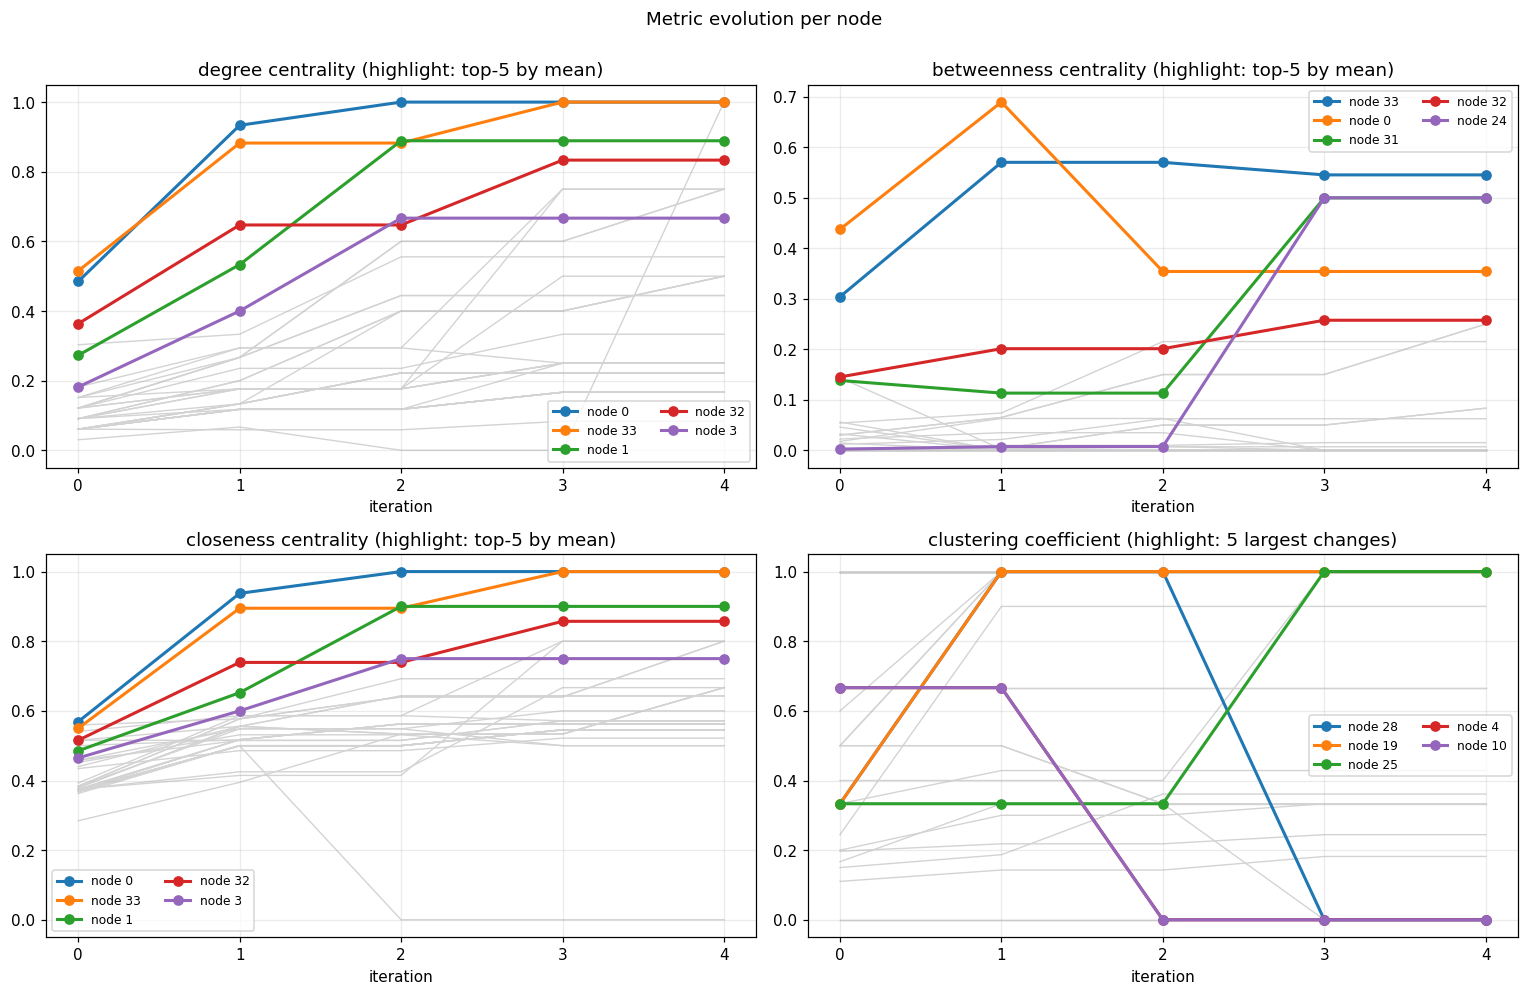

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, name in zip(axes.ravel(), metric_funcs):
    M = tables[name].values                        # n x T
    if name == "clustering coefficient":           # many ties at exactly 1.0 -> highlight the biggest movers instead
        top = np.argsort(-(M.max(axis=1) - M.min(axis=1)))[:5]
    else:
        top = np.argsort(-M.mean(axis=1))[:5]
    for v in nodes: ax.plot(iters, M[v], color="lightgrey", lw=0.9, zorder=1)
    for rank, v in enumerate(top):
        ax.plot(iters, M[v], "o-", color=palette[rank], lw=2, label=f"node {v}", zorder=3)
    ax.set_title(name + (" (highlight: 5 largest changes)" if name == "clustering coefficient" else " (highlight: top-5 by mean)"))
    ax.set_xlabel("iteration"); ax.set_xticks(iters); ax.grid(alpha=.25); ax.legend(fontsize=8, ncol=2)
plt.suptitle("Metric evolution per node", y=1.0)
plt.tight_layout(); plt.savefig("metric_lines.png", bbox_inches="tight"); plt.show()

**(b)** Heat-maps – all 34 nodes × all iterations, with consistent node labelling on the y-axis.

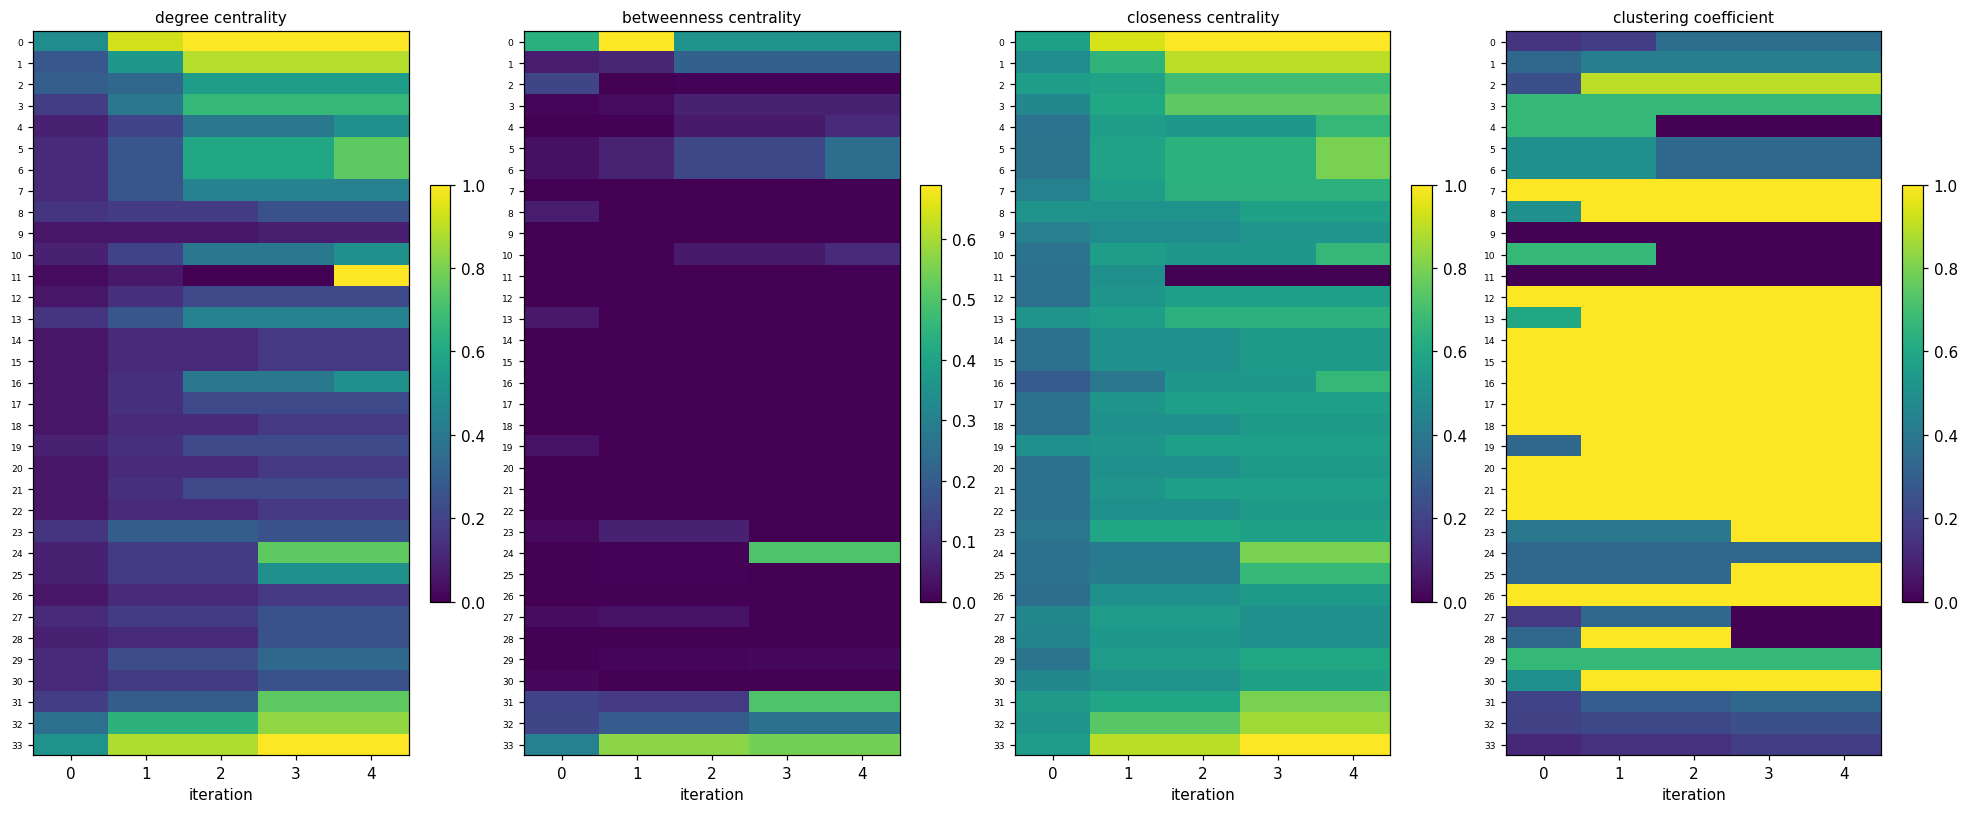

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(18, 7.5))
for ax, name in zip(axes, metric_funcs):
    M = tables[name].values
    im = ax.imshow(M, aspect="auto", cmap="viridis")
    ax.set_title(name, fontsize=10); ax.set_xlabel("iteration")
    ax.set_xticks(range(len(iters))); ax.set_xticklabels(iters)
    ax.set_yticks(range(n)); ax.set_yticklabels(nodes, fontsize=6)
    plt.colorbar(im, ax=ax, fraction=0.05)
plt.tight_layout(); plt.savefig("metric_heatmaps.png", bbox_inches="tight"); plt.show()

**(c)** Bar plots – every node, iteration 0 (whole graph) vs. the final iteration (inside final communities).

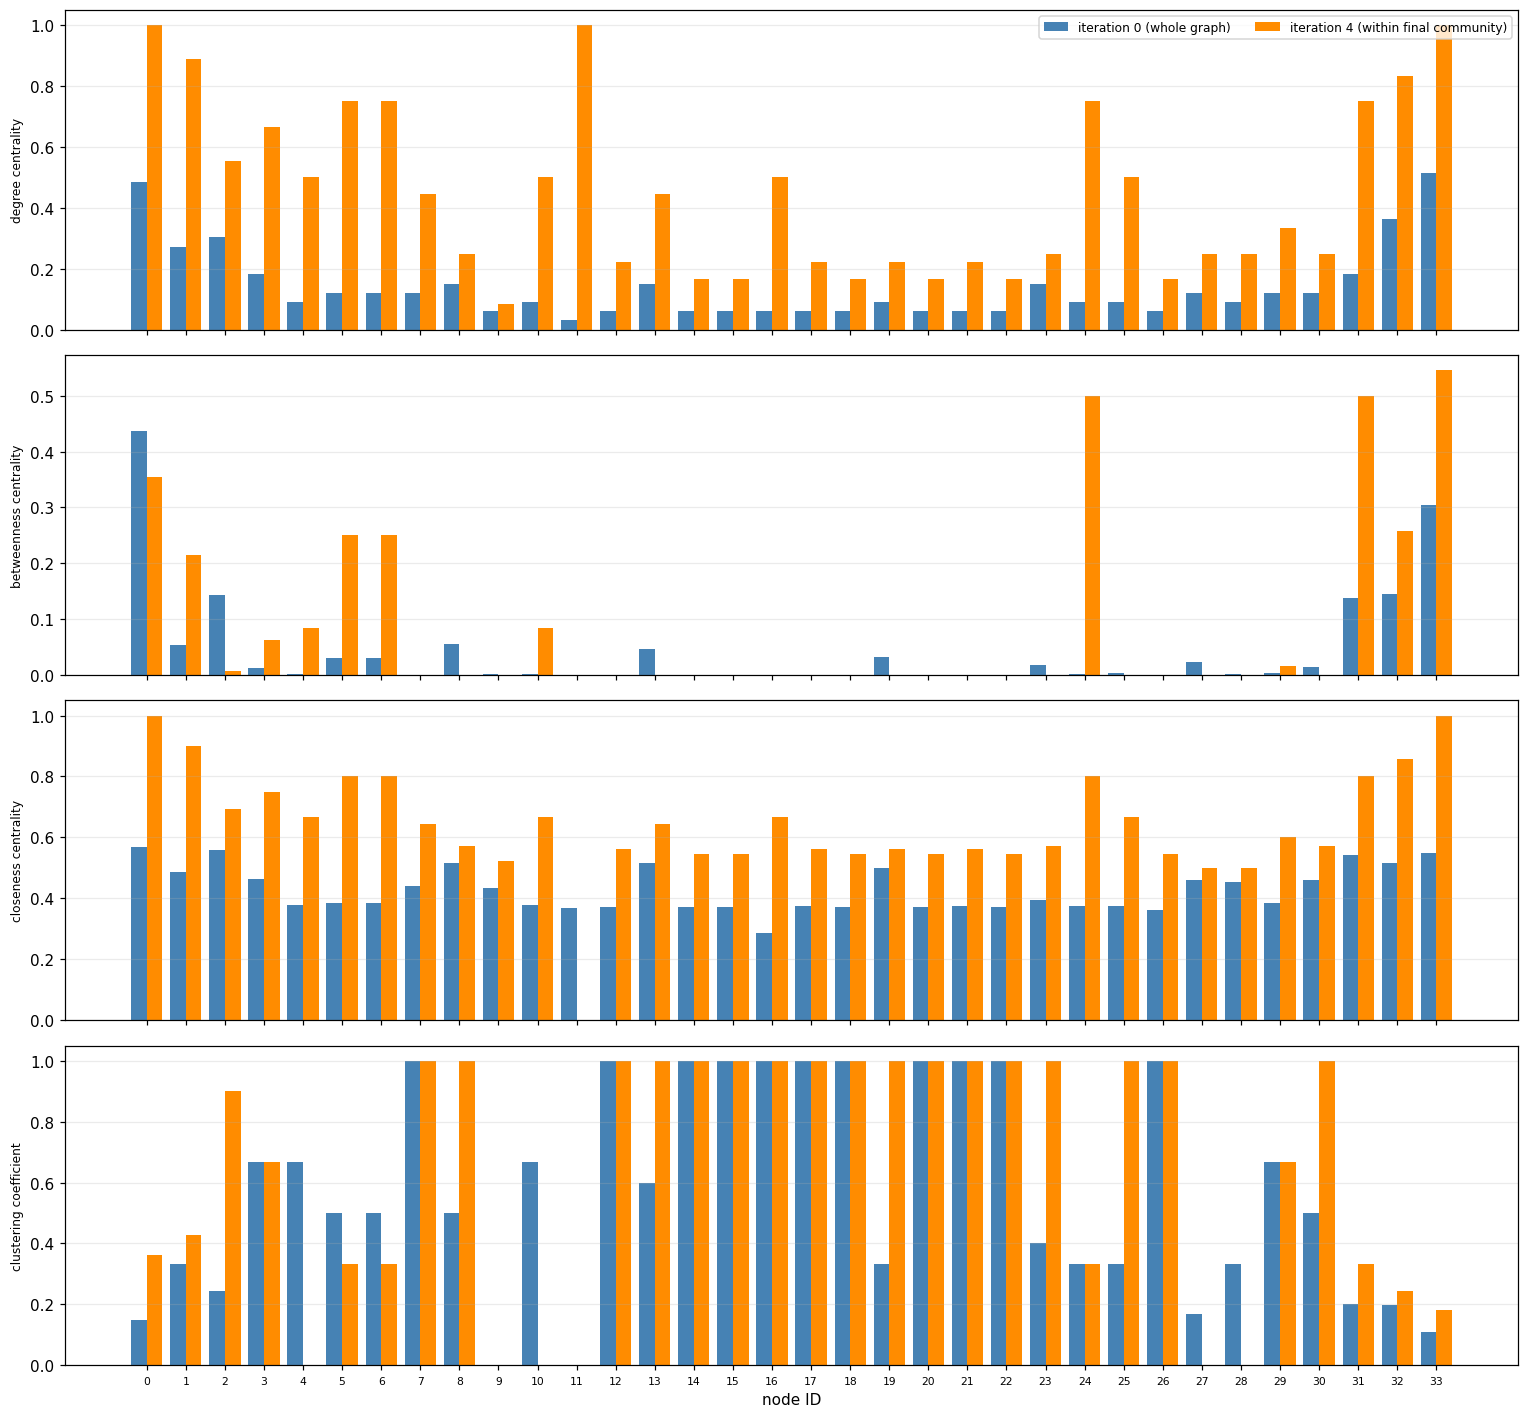

In [24]:
last = iters[-1]
fig, axes = plt.subplots(4, 1, figsize=(14, 13), sharex=True)
x = np.arange(n); wbar = 0.4
for ax, name in zip(axes, metric_funcs):
    ax.bar(x - wbar/2, tables[name][0].values, wbar, label="iteration 0 (whole graph)", color="steelblue")
    ax.bar(x + wbar/2, tables[name][last].values, wbar, label=f"iteration {last} (within final community)", color="darkorange")
    ax.set_ylabel(name, fontsize=8); ax.grid(alpha=.25, axis="y")
axes[0].legend(fontsize=8, ncol=2); axes[-1].set_xticks(x); axes[-1].set_xticklabels(nodes, fontsize=7)
axes[-1].set_xlabel("node ID"); plt.tight_layout(); plt.savefig("metric_bars.png", bbox_inches="tight"); plt.show()

**(d)** Rank plots – absolute values change with the community size, so we also track each node's **rank** (1 = most central) which is size-independent. Ties get the average rank. Only the ten nodes that are most central at iteration 0 are drawn.

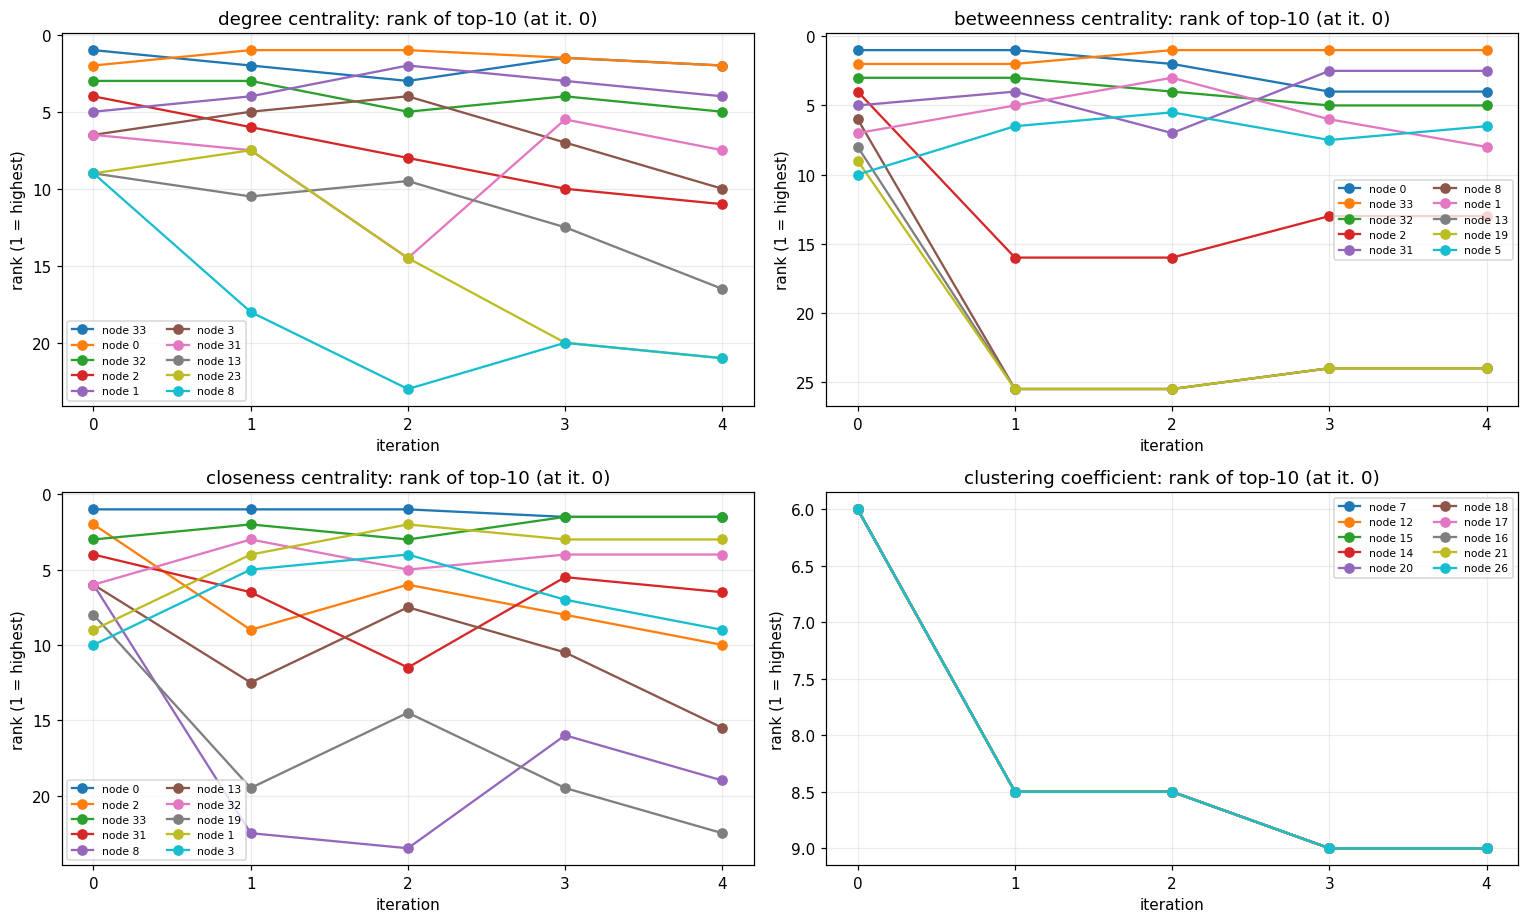

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
for ax, name in zip(axes.ravel(), metric_funcs):
    R = tables[name].rank(ascending=False, method="average")     # rank 1 = highest value
    top = R[0].sort_values().index[:10]
    for v in top:
        ax.plot(iters, R.loc[v].values, "o-", label=f"node {v}")
    ax.invert_yaxis(); ax.set_title(f"{name}: rank of top-10 (at it. 0)")
    ax.set_xlabel("iteration"); ax.set_ylabel("rank (1 = highest)"); ax.set_xticks(iters); ax.grid(alpha=.25)
    ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig("metric_ranks.png", bbox_inches="tight"); plt.show()

           degree centrality  betweenness centrality  closeness centrality  clustering coefficient
iteration                                                                                         
0                      0.139                   0.044                 0.426                   0.571
1                      0.251                   0.057                 0.556                   0.684
2                      0.335                   0.060                 0.575                   0.640
3                      0.406                   0.084                 0.617                   0.641
4                      0.453                   0.092                 0.639                   0.641


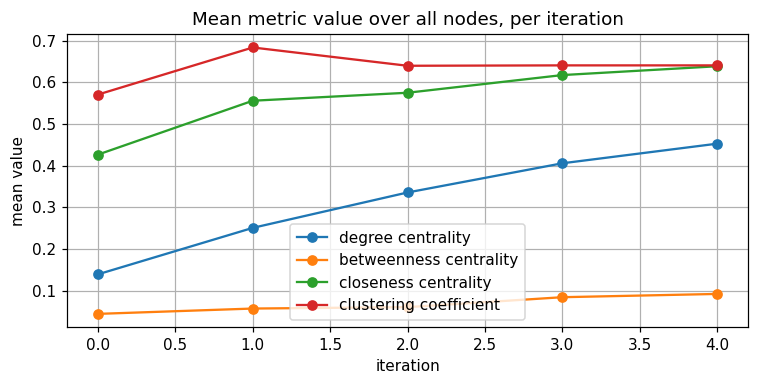

In [26]:
# Average of each metric over all nodes, per iteration (community structure makes the metrics "local")
summary = pd.DataFrame({name: tables[name].mean() for name in metric_funcs})
summary.index.name = "iteration"
print(summary.round(3).to_string())
ax = summary.plot(marker="o", figsize=(7, 3.6), grid=True, title="Mean metric value over all nodes, per iteration")
ax.set_ylabel("mean value"); plt.tight_layout(); plt.savefig("metric_means.png"); plt.show()

## 12. Which nodes stay central? Community-level analysis

In [27]:
# How often does each node appear in the top-5 of each metric across iterations?
top_counts = {}
for name in metric_funcs:
    cnt = Counter()
    for it in iters:
        vals = metric_history[name][it]
        # ties broken by node id so the count is reproducible; singleton communities (value 1/0) can create ties
        cnt.update(sorted(vals, key=lambda v: (-round(vals[v], 12), v))[:5])
    top_counts[name] = cnt
tc = pd.DataFrame(top_counts).fillna(0).astype(int)
tc["total"] = tc.sum(axis=1)
print(f"Top-5 appearances over the {len(iters)} iterations (max possible {len(iters)} per metric):")
tc.sort_values("total", ascending=False).head(10)

Top-5 appearances over the 5 iterations (max possible 5 per metric):


,degree centrality,betweenness centrality,closeness centrality,clustering coefficient,total
33,5,5,5,0,15
0,5,5,5,0,15
32,5,5,4,0,14
1,5,2,4,0,11
31,0,4,1,0,5
14,0,0,0,5,5
12,0,0,0,5,5
7,0,0,0,5,5
8,0,0,1,4,5
13,0,0,0,4,4


*Caution for the clustering column:* many nodes have clustering exactly 1 (or 0) inside small communities, so the "top 5" is decided mostly by ties (broken here by node ID) and carries little meaning. For clustering, look at the heat-map and rank plot instead; degree, betweenness and closeness have few ties and their top-5 counts are reliable.

In [28]:
# Agreement between the metrics on the whole graph (iteration 0): Spearman correlation via ranks
it0 = pd.DataFrame({name: tables[name][0] for name in metric_funcs})
print("Spearman rank correlation of the four metrics on the whole graph:")
it0.rank().corr().round(2)

Spearman rank correlation of the four metrics on the whole graph:


,degree centrality,betweenness centrality,closeness centrality,clustering coefficient
degree centrality,1.00,0.90,0.89,-0.53
betweenness centrality,0.90,1.00,0.90,-0.73
closeness centrality,0.89,0.90,1.00,-0.64
clustering coefficient,-0.53,-0.73,-0.64,1.00


In [29]:
# Community-level table: size, internal density, edges leaving, internal hub
rows = []
purity = sum(max(Counter(G.nodes[v]["club"] for v in c).values()) for c in final_comms) / n
print(f"Faction purity of the final communities: {purity:.1%}  "
      f"(share of members that sit in the majority faction of their community)")
lab_final = community_labels(final_comms)
for cid, c in enumerate(sorted(final_comms, key=min)):
    sub = G.subgraph(c)
    inside = sub.number_of_edges()
    outside = sum(1 for u in c for v in G[u] if v not in set(c))
    hub = max(c, key=lambda v: sub.degree(v)) if len(c) > 1 else c[0]
    rows.append({"community": f"C{cid+1}", "size": len(c), "members": c,
                 "internal edges": inside, "edges leaving": outside,
                 "internal density": round(nx.density(sub), 2) if len(c) > 1 else np.nan,
                 "internal hub": hub,
                 "factions inside": dict(Counter(G.nodes[v]["club"] for v in c))})
pd.DataFrame(rows).set_index("community")

Faction purity of the final communities: 97.1%  (share of members that sit in the majority faction of their community)


,size,members,internal edges,edges leaving,internal density,internal hub,factions inside
community,,,,,,,
C1,10,"[0, 1, 2, 3, 7, 12, 13, 17, 19, 21]",22,15,0.49,0,{'Mr. Hi': 10}
C2,5,"[4, 5, 6, 10, 16]",6,4,0.60,5,{'Mr. Hi': 5}
C3,13,"[8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32,...",24,13,0.31,33,"{'Mr. Hi': 1, 'Officer': 12}"
C4,1,[11],0,1,NaN,11,{'Mr. Hi': 1}
C5,5,"[24, 25, 27, 28, 31]",5,9,0.50,24,{'Officer': 5}


In [30]:
# Key nodes: metric before and after, plus whether their *role* is local hub or global bridge
key_nodes = [0, 33, 32, 2, 1, 31, 8, 11]
rows = []
for v in key_nodes:
    r = {"node": v, "real faction": G.nodes[v]["club"], "final comm.": f"C{lab_final[v]+1}", "degree": int(k[v])}
    for name in metric_funcs:
        r[name.split()[0][:5] + " it0"] = round(tables[name].loc[v, 0], 3)
        r[name.split()[0][:5] + f" it{last}"] = round(tables[name].loc[v, last], 3)
    rows.append(r)
pd.DataFrame(rows).set_index("node")

,real faction,final comm.,degree,degre it0,degre it4,betwe it0,betwe it4,close it0,close it4,clust it0,clust it4
node,,,,,,,,,,,
0,Mr. Hi,C1,16,0.485,1.000,0.438,0.354,0.569,1.000,0.150,0.361
33,Officer,C3,17,0.515,1.000,0.304,0.545,0.550,1.000,0.110,0.182
32,Officer,C3,12,0.364,0.833,0.145,0.258,0.516,0.857,0.197,0.244
2,Mr. Hi,C1,10,0.303,0.556,0.144,0.007,0.559,0.692,0.244,0.900
1,Mr. Hi,C1,9,0.273,0.889,0.054,0.215,0.485,0.900,0.333,0.429
31,Officer,C5,6,0.182,0.750,0.138,0.500,0.541,0.800,0.200,0.333
8,Mr. Hi,C3,5,0.152,0.250,0.056,0.000,0.516,0.571,0.500,1.000
11,Mr. Hi,C4,1,0.030,1.000,0.000,0.000,0.367,0.000,0.000,0.000


In [31]:
# Betweenness lost when the graph is cut: nodes whose brokerage was *between* communities
b0, bL = tables["betweenness centrality"][0], tables["betweenness centrality"][last]
chg = (bL - b0).sort_values()
print("Largest betweenness drops (it0 -> final): nodes whose brokerage was between communities")
print(chg.head(5).round(3).to_string())
print("\nLargest betweenness gains: local brokers inside their community")
print(chg.tail(5).round(3).to_string())

# Global bridges: nodes with edges to several different final communities
bridge = {v: len({lab_final[u] for u in G[v]} - {lab_final[v]}) for v in nodes}
print("\nNodes linked to the most OTHER communities:", sorted(bridge.items(), key=lambda t: -t[1])[:5])

Largest betweenness drops (it0 -> final): nodes whose brokerage was between communities
2    -0.137
0    -0.083
8    -0.056
13   -0.046
19   -0.032

Largest betweenness gains: local brokers inside their community
5     0.220
6     0.220
33    0.241
31    0.362
24    0.498

Nodes linked to the most OTHER communities: [(0, 4), (2, 2), (27, 2), (28, 2), (31, 2)]


## 13. Extension: vertex-move refinement
Rounding $u_1$ by sign is a one-shot heuristic. Newman (2006) notes that it can be improved by moving single vertices while that increases $Q$ (a Kernighan–Lin-style step). Starting from the spectral two-way split we greedily move the single vertex that raises $Q$ most until no move helps.

In [32]:
def refine(s, B, m, verbose=True):
    s = s.copy(); moves = []
    while True:
        base = s @ B @ s / (4 * m)
        best, best_v = 0, None
        for v in range(len(s)):
            t = s.copy(); t[v] *= -1
            gain = t @ B @ t / (4 * m) - base
            if gain > best + 1e-12: best, best_v = gain, v
        if best_v is None: break
        s[best_v] *= -1; moves.append((int(best_v), round(float(best), 4)))
    return s, moves

s0 = np.where(u1 > 0, 1, -1)
s_ref, moves = refine(s0, B, m)
print(f"spectral rounding  Q = {s0 @ B @ s0 / (4*m):.4f}   (agreement with factions {max((s0==(1-2*truth)).mean(), (s0!=(1-2*truth)).mean()):.1%})")
print(f"after refinement   Q = {s_ref @ B @ s_ref / (4*m):.4f}   moves (node, gain): {moves}")
tr = 1 - 2 * truth
print(f"agreement with factions after refinement: {max((s_ref==tr).mean(), (s_ref!=tr).mean()):.1%}")

spectral rounding  Q = 0.3715   (agreement with factions 97.1%)
after refinement   Q = 0.3718   moves (node, gain): [(9, 0.0003)]
agreement with factions after refinement: 94.1%


The refinement changes the two-way modularity only slightly (one move, gain $\approx 3\times10^{-4}$), so the spectral rounding was already almost a local optimum for the bipartition problem. Note, however, that the move *lowers* the agreement with the real factions (node 9 is pulled to the wrong side): **maximising modularity is not the same as recovering the ground truth**, a limitation of any modularity-based method.

## 14. Discussion
All numbers below are produced by the cells above (the computation is deterministic; eigenvector signs from `eigh` may flip, which only swaps the labels $\pm1$, never the partition).

### 14.1 What the method found
* **First split.** The leading eigenvalue of $B$ is $\lambda_1=4.977$ and splitting by the sign of $u_1$ gives groups of 16 and 18 members, cutting 10 edges with $Q=0.3715$. This is even *higher* than the modularity of the real faction split ($Q=0.3582$, 11 edges cut). It agrees with the real factions on **33 of 34 members** (97.1 %; ARI 0.88, NMI 0.84).
* **The one error is node 8.** Node 8 (really in Mr. Hi's faction) has five neighbours: two in Mr. Hi's side (0, 2) and three in the Officer side (30, 32, 33). Judged only on the graph it sits slightly closer to the president's side, and the entries of $u_1$ confirm this: nodes 9, 8, 24, 19, 16 have the entries closest to 0 (the least certain assignments). This is an inherent limit of a structure-only method, not a coding error.
* **Recursion.** Further splits are all accepted by the eigenvalue test and have positive true $\Delta Q$: $+0.0183$ (16 → 10 + 6), $+0.0183$ (18 → 5 + 13), $+0.0013$ (6 → 1 + 5). The gains shrink quickly, which is the signature of reaching the natural resolution of the graph. The process stops at **5 communities with $Q=0.4094$**: $\{0,1,2,3,7,12,13,17,19,21\}$, $\{4,5,6,10,16\}$, $\{8,9,14,15,18,20,22,23,26,29,30,32,33\}$, $\{11\}$, $\{24,25,27,28,31\}$.
* **Relation to the real split.** The final communities are a *refinement* of the real factions: three of them are pure Mr. Hi or pure Officer, the large Officer community contains node 8 as its only intruder, and the 5th is the singleton $\{11\}$ (a degree-1 node attached to node 0). Faction purity is 97.1 %. So the algorithm recovers the real split and additionally exposes sub-groups, for example the group {4, 5, 6, 10, 16} that hangs off Mr. Hi, and {24, 25, 27, 28, 31} on the president's side.
* **Comparison with other algorithms.** With Newman's exact generalised matrix the recursion gives 4 communities with $Q=0.3934$; NetworkX's greedy modularity gives 3 communities ($Q=0.381$) and Louvain gives 4 communities with $Q=0.4188$, higher than our spectral result. This is expected: one-shot sign rounding is a greedy heuristic and the Louvain result is close to the best value usually reported for this graph. Low ARI/NMI values for the finer partitions do not mean they are "wrong": they simply have more groups than the two real factions.

### 14.2 Which nodes consistently remain central?
* **Nodes 0 and 33** (Mr. Hi and the president) are in the top 5 for degree, betweenness *and* closeness at **every one of the 5 iterations**. **Node 32** is in the top 5 for degree and betweenness at every iteration and for closeness in 4 of 5. **Node 1** is a stable top-5 node for degree (5/5) and closeness (4/5). **Node 31** is a recurring top-5 broker by betweenness (4/5): it connects the group {24, 25, 27, 28} to the rest of the president's side and to node 0.
* The three centralities agree strongly on the whole graph (Spearman correlation between 0.89 and 0.90), so the same few hubs lead all three rankings, whereas the **clustering coefficient is negatively correlated** with them (−0.53 with degree, −0.73 with betweenness, −0.64 with closeness): hubs link otherwise unconnected groups, so their neighbours rarely know each other (global clustering 0.15 for node 0 and 0.11 for node 33), while low-degree members of tight cliques (nodes 7, 14, 15, …) have clustering 1.
* The leaders are the two faction leaders. This is precisely the structure that caused the split: two high-degree hubs, each surrounded by its own followers.

### 14.3 How community structure influences each metric
Metrics were computed inside each node's community (Section 10), so every change below is caused by the cutting of the graph.
* **Degree and closeness mostly rise.** The mean degree centrality over all nodes goes from 0.139 to 0.453 and mean closeness from 0.426 to 0.639. Part of this is a *size effect* (the normaliser $n_C-1$ shrinks), part is real: communities are dense, so members are close to each other. Node 0 goes from 0.485 to 1.0 (degree) and 0.569 to 1.0 (closeness): it is adjacent to every other member of its community. Because the effect is common to all nodes, the **ranks** (Section 11d) are the right quantity for comparing nodes across iterations, and they show the same hubs on top.
* **Betweenness separates global bridges from local brokers.** Node 0's betweenness jumps to 0.690 inside its 16-node half (iteration 1), then falls to 0.354 once its half is split further, and node 2's collapses from 0.144 to 0.007: much of their brokerage consisted of shortest paths *between* communities, which disappear when those communities are separated. Node 0 touches **four other final communities**, which is the structural reason why it is the main global bridge. In contrast node 33 rises from 0.304 to 0.545, node 31 from 0.138 to 0.500 and node 24 from about 0 to 0.498: they are the connectors *inside* their own communities, so cutting the graph makes them look more important. In short, high betweenness in the full graph can reflect a role *between* groups, high betweenness inside a community reflects a role *within* it.
* **Clustering rises inside cliquish communities.** Node 2 goes from 0.244 to 0.900, node 8 from 0.500 to 1.0 (already at iteration 1), node 0 from 0.150 to 0.361, and the mean clustering goes from 0.571 to 0.641 (peaking at 0.684 at iteration 1). This confirms that the detected groups are locally tightly knit, i.e. the split removes the "weak ties" that lowered the hubs' clustering.
* **Edge cases.** Node 11 is isolated from its only neighbour (node 0) as soon as node 0's group is split off, so its degree and closeness inside the 6-node group are 0, and as a singleton NetworkX returns degree centrality 1 by convention. This is an artefact of the convention and not a sign of centrality.

### 14.4 Limitations
1. The interpretation of "metrics after each split" (within-community computation) is a modelling choice; whole-graph values never change under recolouring.
2. The handout's plain restricted block differs from Newman's exact generalised matrix (Section 6); a positive $\lambda_1$ does not guarantee a positive gain after rounding to $\pm1$, which is why the true $\Delta Q$ is also checked.
3. Modularity has a **resolution limit** and maximising it is not the same as recovering ground-truth labels: the refinement experiment (Section 13) raises $Q$ slightly but moves one more node into the wrong faction.
4. With only 34 nodes some ties and tiny communities (singletons) appear, and their metrics are degenerate (Section 12).


## 15. Exam-preparation Q&A
**Q1. What does $B_{ij}=A_{ij}-k_ik_j/2m$ measure?** The surplus of the observed edge count between $i$ and $j$ over what a degree-preserving random graph (stub pairing) would give; $s^\top Bs/4m$ sums these surpluses for pairs on the same side and subtracts them for pairs on opposite sides.

**Q2. Why is $B\mathbf 1=0$ and what does it imply?** $A\mathbf 1=k$ and $k(k^\top\mathbf 1)/2m=k$, so $B\mathbf 1=0$: $\mathbf 1$ is an eigenvector with eigenvalue 0, and the trivial one-community partition has $Q=0$.

**Q3. Why is the leading eigenvector the right object?** Relaxing $s\in\{\pm1\}^n$ to $\|s\|_2=1$ turns the problem into maximising a quadratic form; by Rayleigh–Ritz the maximum is $\lambda_1$ at $u_1$ (since $s^\top Bs=\sum\alpha_i^2\lambda_i\le\lambda_1$). We then round by sign.

**Q4. Why stop when $\lambda_1^{(C)}\le0$?** Then $x^\top B^{(C)}x\le\lambda_1\|x\|^2\le0$ for every $x$, so no split vector can have a positive gain. (Subtlety: the exact gain uses Newman's generalised matrix $B^{(g)}$, and a positive $\lambda_1$ does not by itself guarantee a gain after rounding, so we also check the true $\Delta Q$.)

**Q5. Why does the global $B$ always have eigenvalue 0 but $B^{(C)}$ need not?** The row-sum identity $B\mathbf 1=0$ uses all $n$ columns; a restricted block drops columns, so its row sums are generally non-zero and $0$ is not forced to be an eigenvalue. (In this run the 1-node group $\{11\}$ has $\lambda_1<0$.)

**Q6. Why not minimise the cut?** The minimum cut isolates tiny pieces (e.g. node 11, cut size 1, $Q\approx0$); modularity compares with a null model and rewards unexpectedly dense groups (Section 2).

**Q7. How does community structure affect centrality?** Degree and closeness are inflated inside dense groups, global bridges lose betweenness when the graph is cut while local brokers gain, and clustering rises inside cliquish communities (Sections 10–12, 14).

## 16. References
* M. E. J. Newman (2006). *Modularity and community structure in networks.* PNAS 103(23):8577–8582.
* M. E. J. Newman (2006). *Finding community structure in networks using the eigenvectors of matrices.* Phys. Rev. E 74, 036104.
* W. W. Zachary (1977). *An information flow model for conflict and fission in small groups.* Journal of Anthropological Research 33(4):452–473.
* NetworkX documentation: `degree_centrality`, `betweenness_centrality`, `closeness_centrality`, `clustering`, `configuration_model`, `louvain_communities`.